# Olist delivery delay analysis

Independent SQL portfolio project by Azra Ar using the Brazilian E-Commerce Public Dataset by Olist.

Run the code cells from top to bottom in Google Colab. Three upload prompts request four CSV files in total.

1. Upload `olist_orders_dataset.csv` at the first prompt.
2. Upload `olist_order_items_dataset.csv` and `olist_products_dataset.csv` together at the second prompt.
3. Upload `olist_customers_dataset.csv` at the third prompt.

The notebook loads the data into an in-memory SQLite database. Reconnects or runtime resets require rerunning the upload cells. Saved table and chart outputs document the submitted run.


In [ ]:
from google.colab import files
from io import BytesIO
import pandas as pd
import sqlite3

uploaded = files.upload()
csv_bytes = next(iter(uploaded.values()))
orders = pd.read_csv(BytesIO(csv_bytes))

conn = sqlite3.connect(":memory:")
orders.to_sql("orders", conn, index=False, if_exists="replace")

print(f"{len(orders)} sipariş kaydı SQL tablosuna yüklendi.")

## Preview the order table

Each source order has its own order ID. Start by inspecting status and delivery dates.

In [ ]:
query = """
SELECT
    order_status,
    order_delivered_customer_date,
    order_estimated_delivery_date
FROM orders
LIMIT 5;
"""

pd.read_sql_query(query, conn)

,order_status,order_delivered_customer_date,order_estimated_delivery_date
0,delivered,2017-10-10 21:25:13,2017-10-18 00:00:00
1,delivered,2018-08-07 15:27:45,2018-08-13 00:00:00
2,delivered,2018-08-17 18:06:29,2018-09-04 00:00:00
3,delivered,2017-12-02 00:28:42,2017-12-15 00:00:00
4,delivered,2018-02-16 18:17:02,2018-02-26 00:00:00


## Overall delivery performance

Compare calendar dates so a delivery on the estimated day counts as on time. The denominator contains delivered orders with valid actual and estimated delivery dates.

In [ ]:
query = """
SELECT
    COUNT(*) AS delivered_orders,
    SUM(
        CASE WHEN DATE(order_delivered_customer_date)
                > DATE(order_estimated_delivery_date)
             THEN 1 ELSE 0 END
    ) AS late_orders,
    ROUND(
        100.0 * AVG(
            CASE WHEN DATE(order_delivered_customer_date)
                    > DATE(order_estimated_delivery_date)
                 THEN 1 ELSE 0 END
        ), 2
    ) AS late_rate_pct
FROM orders
WHERE order_status = 'delivered'
  AND DATE(order_delivered_customer_date) IS NOT NULL
  AND DATE(order_estimated_delivery_date) IS NOT NULL;
"""

pd.read_sql_query(query, conn)

,delivered_orders,late_orders,late_rate_pct
0,96470,6534,6.77


In [ ]:
query = """
SELECT
    COUNT(*) AS late_orders,
    ROUND(
        AVG(
            JULIANDAY(DATE(order_delivered_customer_date))
            - JULIANDAY(DATE(order_estimated_delivery_date))
        ), 2
    ) AS average_delay_days,
    CAST(
        MAX(
            JULIANDAY(DATE(order_delivered_customer_date))
            - JULIANDAY(DATE(order_estimated_delivery_date))
        ) AS INTEGER
    ) AS maximum_delay_days
FROM orders
WHERE order_status = 'delivered'
  AND DATE(order_delivered_customer_date)
      > DATE(order_estimated_delivery_date);
"""

pd.read_sql_query(query, conn)

,late_orders,average_delay_days,maximum_delay_days
0,6534,10.62,188


## Delivery stages and date quality

Measure time before carrier handover and time in transit. Stage comparisons retain complete, nonnegative durations. Their population is smaller than the overall delivery-date population.

In [ ]:
query = """
WITH delivery_times AS (
    SELECT
        CASE
            WHEN DATE(order_delivered_customer_date)
                 > DATE(order_estimated_delivery_date)
            THEN 'Late'
            ELSE 'On time'
        END AS delivery_group,

        JULIANDAY(order_delivered_carrier_date)
        - JULIANDAY(order_purchase_timestamp)
            AS before_carrier_days,

        JULIANDAY(order_delivered_customer_date)
        - JULIANDAY(order_delivered_carrier_date)
            AS transit_days

    FROM orders
    WHERE order_status = 'delivered'
      AND DATE(order_estimated_delivery_date) IS NOT NULL
)
SELECT
    delivery_group,
    COUNT(*) AS orders_compared,
    ROUND(AVG(before_carrier_days), 2)
        AS avg_before_carrier_days,
    ROUND(AVG(transit_days), 2)
        AS avg_transit_days
FROM delivery_times
WHERE before_carrier_days >= 0
  AND transit_days >= 0
GROUP BY delivery_group;
"""

pd.read_sql_query(query, conn)

,delivery_group,orders_compared,avg_before_carrier_days,avg_transit_days
0,Late,6531,6.06,27.89
1,On time,89750,3.03,7.98


In [ ]:
query = """
WITH durations AS (
    SELECT
        JULIANDAY(order_delivered_carrier_date)
        - JULIANDAY(order_purchase_timestamp) AS before_carrier,

        JULIANDAY(order_delivered_customer_date)
        - JULIANDAY(order_delivered_carrier_date) AS transit

    FROM orders
    WHERE order_status = 'delivered'
      AND DATE(order_delivered_customer_date) IS NOT NULL
      AND DATE(order_estimated_delivery_date) IS NOT NULL
)
SELECT
    COUNT(*) AS total_orders,

    SUM(CASE
        WHEN before_carrier IS NULL OR transit IS NULL
        THEN 1 ELSE 0
    END) AS missing_or_unreadable_dates,

    SUM(CASE
        WHEN before_carrier IS NOT NULL
         AND transit IS NOT NULL
         AND (before_carrier < 0 OR transit < 0)
        THEN 1 ELSE 0
    END) AS inconsistent_date_order
FROM durations;
"""

pd.read_sql_query(query, conn)

,total_orders,missing_or_unreadable_dates,inconsistent_date_order
0,96470,1,188


## Product categories

Load order items and product metadata. Group items by order before aggregation. Include an order only when every item has a known category and all items share that category. Category rankings require at least 100 eligible delivered orders.

In [ ]:
uploaded_products = files.upload()

file_tables = {
    "olist_order_items_dataset.csv": "order_items",
    "olist_products_dataset.csv": "products"
}

for filename, table_name in file_tables.items():
    table = pd.read_csv(BytesIO(uploaded_products[filename]))
    table.to_sql(
        table_name,
        conn,
        index=False,
        if_exists="replace"
    )
    print(f"{table_name}: {len(table)} satır yüklendi.")

In [ ]:
category_query = """
WITH order_categories AS (
    SELECT
        oi.order_id,
        MIN(p.product_category_name) AS category
    FROM order_items AS oi
    LEFT JOIN products AS p
        ON oi.product_id = p.product_id
    GROUP BY oi.order_id
    HAVING COUNT(DISTINCT p.product_category_name) = 1
       AND COUNT(p.product_category_name) = COUNT(*)
),
category_results AS (
    SELECT
        c.category,
        COUNT(*) AS delivered_orders,
        SUM(
            CASE
                WHEN DATE(o.order_delivered_customer_date)
                     > DATE(o.order_estimated_delivery_date)
                THEN 1 ELSE 0
            END
        ) AS late_orders
    FROM orders AS o
    JOIN order_categories AS c
        ON o.order_id = c.order_id
    WHERE o.order_status = 'delivered'
      AND DATE(o.order_delivered_customer_date) IS NOT NULL
      AND DATE(o.order_estimated_delivery_date) IS NOT NULL
    GROUP BY c.category
)
SELECT
    category,
    delivered_orders,
    late_orders,
    ROUND(
        100.0 * late_orders / delivered_orders, 2
    ) AS late_rate_pct
FROM category_results
WHERE delivered_orders >= 100
ORDER BY late_rate_pct DESC
LIMIT 10;
"""

category_summary = pd.read_sql_query(category_query, conn)
display(category_summary)

,category,delivered_orders,late_orders,late_rate_pct
0,audio,342,41,11.99
1,casa_conforto,342,35,10.23
2,fashion_underwear_e_moda_praia,117,11,9.40
3,livros_tecnicos,252,21,8.33
4,bebes,2716,224,8.25
5,moveis_escritorio,1239,101,8.15
6,artigos_de_natal,124,10,8.06
7,moveis_sala,398,31,7.79
8,eletronicos,2494,192,7.70
9,instrumentos_musicais,603,46,7.63


In [ ]:
volume_query = category_query.replace(
    "ORDER BY late_rate_pct DESC",
    "ORDER BY late_orders DESC, late_rate_pct DESC"
)

category_priority = pd.read_sql_query(volume_query, conn)
display(category_priority)

,category,delivered_orders,late_orders,late_rate_pct
0,cama_mesa_banho,9069,684,7.54
1,beleza_saude,8576,648,7.56
2,esporte_lazer,7457,493,6.61
3,moveis_decoracao,6103,446,7.31
4,informatica_acessorios,6478,417,6.44
5,relogios_presentes,5453,406,7.45
6,utilidades_domesticas,5627,307,5.46
7,telefonia,4066,291,7.16
8,automotivo,3773,278,7.37
9,brinquedos,3752,241,6.42


## Selected category

Inspect cama_mesa_banho because it has the largest late-order count in the eligible category ranking. Compare stages for on-time and late orders.

In [ ]:
query = """
WITH order_categories AS (
    SELECT
        oi.order_id,
        MIN(p.product_category_name) AS category
    FROM order_items AS oi
    LEFT JOIN products AS p
        ON oi.product_id = p.product_id
    GROUP BY oi.order_id
    HAVING COUNT(DISTINCT p.product_category_name) = 1
       AND COUNT(p.product_category_name) = COUNT(*)
),
category_times AS (
    SELECT
        CASE
            WHEN DATE(o.order_delivered_customer_date)
                 > DATE(o.order_estimated_delivery_date)
            THEN 'Late'
            ELSE 'On time'
        END AS delivery_group,

        JULIANDAY(o.order_delivered_carrier_date)
        - JULIANDAY(o.order_purchase_timestamp)
            AS before_carrier_days,

        JULIANDAY(o.order_delivered_customer_date)
        - JULIANDAY(o.order_delivered_carrier_date)
            AS transit_days

    FROM orders AS o
    JOIN order_categories AS c
        ON o.order_id = c.order_id
    WHERE c.category = 'cama_mesa_banho'
      AND o.order_status = 'delivered'
      AND DATE(o.order_delivered_customer_date) IS NOT NULL
      AND DATE(o.order_estimated_delivery_date) IS NOT NULL
)
SELECT
    delivery_group,
    COUNT(*) AS orders_compared,
    ROUND(AVG(before_carrier_days), 2)
        AS avg_before_carrier_days,
    ROUND(AVG(transit_days), 2)
        AS avg_transit_days
FROM category_times
WHERE before_carrier_days >= 0
  AND transit_days >= 0
GROUP BY delivery_group;
"""

category_stage_comparison = pd.read_sql_query(query, conn)
display(category_stage_comparison)

,delivery_group,orders_compared,avg_before_carrier_days,avg_transit_days
0,Late,684,6.01,28.37
1,On time,8366,2.94,8.38


## Destination state comparison

Load customers and join on customer_id. State rankings use the selected category and require at least 100 eligible delivered orders. RJ and SP are compared in more detail because of their late-order counts and rates.

In [ ]:
uploaded_customers = files.upload()

customers = pd.read_csv(
    BytesIO(uploaded_customers["olist_customers_dataset.csv"])
)

customers.to_sql(
    "customers",
    conn,
    index=False,
    if_exists="replace"
)

print(f"customers: {len(customers)} satır yüklendi.")

In [ ]:
query = """
WITH order_categories AS (
    SELECT
        oi.order_id,
        MIN(p.product_category_name) AS category
    FROM order_items AS oi
    LEFT JOIN products AS p
        ON oi.product_id = p.product_id
    GROUP BY oi.order_id
    HAVING COUNT(DISTINCT p.product_category_name) = 1
       AND COUNT(p.product_category_name) = COUNT(*)
),
state_results AS (
    SELECT
        cu.customer_state AS state,
        COUNT(*) AS delivered_orders,
        SUM(
            CASE
                WHEN DATE(o.order_delivered_customer_date)
                     > DATE(o.order_estimated_delivery_date)
                THEN 1 ELSE 0
            END
        ) AS late_orders
    FROM orders AS o
    JOIN order_categories AS c
        ON o.order_id = c.order_id
    JOIN customers AS cu
        ON o.customer_id = cu.customer_id
    WHERE c.category = 'cama_mesa_banho'
      AND o.order_status = 'delivered'
      AND DATE(o.order_delivered_customer_date) IS NOT NULL
      AND DATE(o.order_estimated_delivery_date) IS NOT NULL
    GROUP BY cu.customer_state
)
SELECT
    state,
    delivered_orders,
    late_orders,
    ROUND(
        100.0 * late_orders / delivered_orders, 2
    ) AS late_rate_pct
FROM state_results
WHERE delivered_orders >= 100
ORDER BY late_rate_pct DESC;
"""

state_summary = pd.read_sql_query(query, conn)
display(state_summary)

,state,delivered_orders,late_orders,late_rate_pct
0,ES,191,30,15.71
1,RJ,1330,201,15.11
2,BA,209,30,14.35
3,GO,183,25,13.66
4,SC,263,30,11.41
5,DF,166,15,9.04
6,RS,521,45,8.64
7,MG,1096,73,6.66
8,SP,4258,176,4.13
9,PR,386,13,3.37


In [ ]:
query = """
WITH order_categories AS (
    SELECT
        oi.order_id,
        MIN(p.product_category_name) AS category
    FROM order_items AS oi
    LEFT JOIN products AS p
        ON oi.product_id = p.product_id
    GROUP BY oi.order_id
    HAVING COUNT(DISTINCT p.product_category_name) = 1
       AND COUNT(p.product_category_name) = COUNT(*)
),
delivery_windows AS (
    SELECT
        cu.customer_state AS state,

        JULIANDAY(DATE(o.order_delivered_customer_date))
        - JULIANDAY(DATE(o.order_purchase_timestamp))
            AS actual_delivery_days,

        JULIANDAY(DATE(o.order_estimated_delivery_date))
        - JULIANDAY(DATE(o.order_purchase_timestamp))
            AS promised_delivery_days

    FROM orders AS o
    JOIN order_categories AS c
        ON o.order_id = c.order_id
    JOIN customers AS cu
        ON o.customer_id = cu.customer_id
    WHERE c.category = 'cama_mesa_banho'
      AND cu.customer_state IN ('RJ', 'SP')
      AND o.order_status = 'delivered'
)
SELECT
    state,
    COUNT(*) AS orders_compared,
    ROUND(AVG(actual_delivery_days), 2)
        AS avg_actual_delivery_days,
    ROUND(AVG(promised_delivery_days), 2)
        AS avg_promised_delivery_days
FROM delivery_windows
WHERE actual_delivery_days >= 0
  AND promised_delivery_days >= 0
GROUP BY state;
"""

delivery_window_comparison = pd.read_sql_query(query, conn)
display(delivery_window_comparison)

,state,orders_compared,avg_actual_delivery_days,avg_promised_delivery_days
0,RJ,1330,16.84,27.02
1,SP,4258,9.33,20.47


## Key uniqueness checks

Compare total rows with distinct IDs for orders, products and customers. The submitted run shows equal counts for each table.

In [ ]:
check_query = """
SELECT
    'orders' AS table_name,
    COUNT(*) AS total_rows,
    COUNT(DISTINCT order_id) AS unique_ids
FROM orders

UNION ALL

SELECT
    'products',
    COUNT(*),
    COUNT(DISTINCT product_id)
FROM products

UNION ALL

SELECT
    'customers',
    COUNT(*),
    COUNT(DISTINCT customer_id)
FROM customers;
"""

display(pd.read_sql_query(check_query, conn))

,table_name,total_rows,unique_ids
0,orders,99441,99441
1,products,32951,32951
2,customers,99441,99441


## Visual results

Display the destination-state comparison and the stage-duration comparison for the selected category. All plotted values are descriptive aggregates.

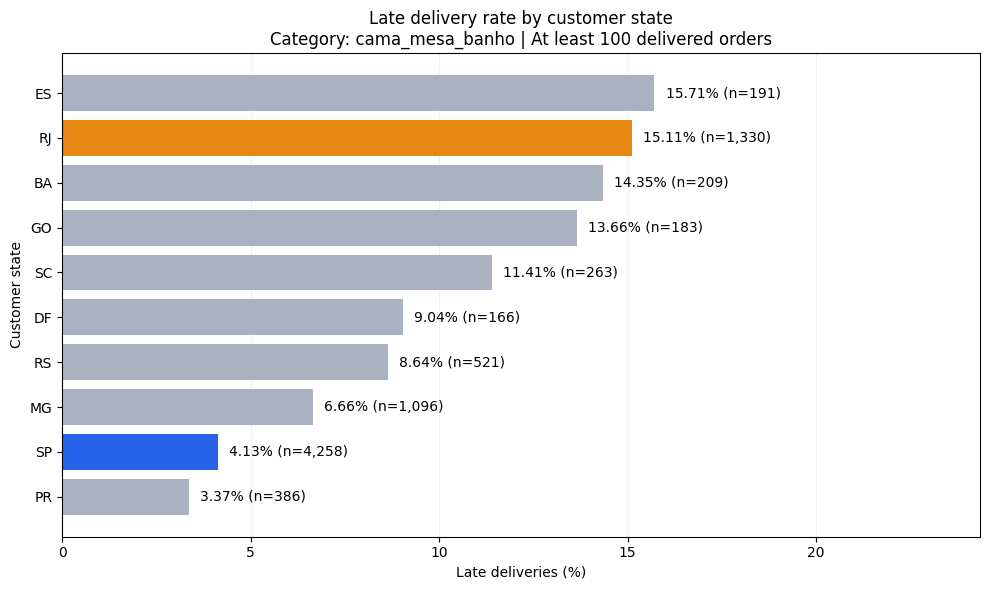

In [ ]:
import matplotlib.pyplot as plt

plot_data = state_summary.sort_values("late_rate_pct")

colors = [
    "#E68613" if state == "RJ"
    else "#2563EB" if state == "SP"
    else "#A8B2C1"
    for state in plot_data["state"]
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_data["state"],
    plot_data["late_rate_pct"],
    color=colors
)

for position, row in enumerate(plot_data.itertuples()):
    ax.text(
        row.late_rate_pct + 0.3,
        position,
        f"{row.late_rate_pct:.2f}% (n={row.delivered_orders:,})",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Late delivery rate by customer state\n"
    "Category: cama_mesa_banho | At least 100 delivered orders"
)
ax.set_xlabel("Late deliveries (%)")
ax.set_ylabel("Customer state")
ax.set_xlim(0, plot_data["late_rate_pct"].max() * 1.55)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("category_state_late_rates.png", dpi=300)
plt.show()

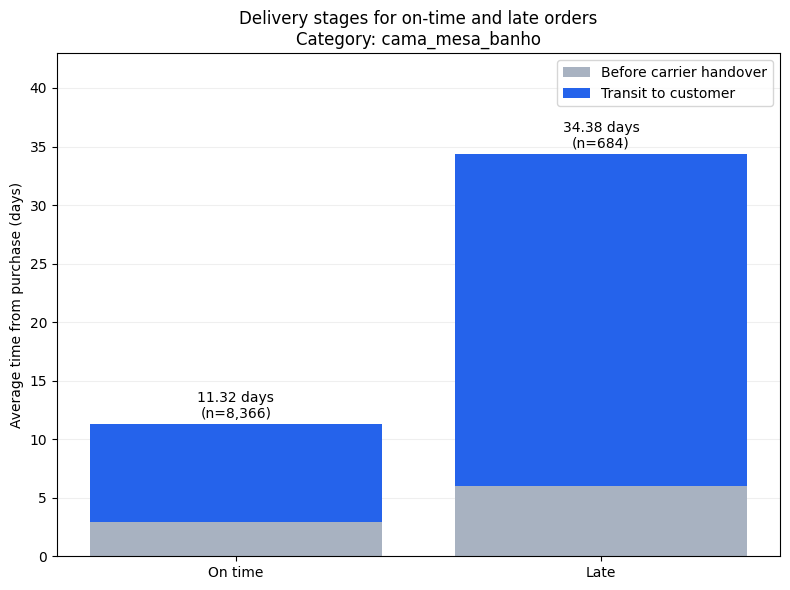

In [ ]:
stage_data = (
    category_stage_comparison
    .set_index("delivery_group")
    .loc[["On time", "Late"]]
)

fig, ax = plt.subplots(figsize=(8, 6))

before = stage_data["avg_before_carrier_days"]
transit = stage_data["avg_transit_days"]
positions = [0, 1]

ax.bar(
    positions, before,
    color="#A8B2C1",
    label="Before carrier handover"
)

ax.bar(
    positions, transit,
    bottom=before,
    color="#2563EB",
    label="Transit to customer"
)

for position, row in enumerate(stage_data.itertuples()):
    total = row.avg_before_carrier_days + row.avg_transit_days

    ax.text(
        position, total + 0.5,
        f"{total:.2f} days\n(n={row.orders_compared:,})",
        ha="center"
    )

ax.set_xticks(positions, ["On time", "Late"])
ax.set_ylabel("Average time from purchase (days)")
ax.set_title(
    "Delivery stages for on-time and late orders\n"
    "Category: cama_mesa_banho"
)
ax.set_ylim(0, (before + transit).max() * 1.25)
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("category_delivery_stages.png", dpi=300)
plt.show()

## Download results

Export the five category and regional tables and two figures from the current Colab run.

In [ ]:
from pathlib import Path
import shutil

results_dir = Path("olist_results")
results_dir.mkdir(exist_ok=True)

tables = {
    "category_late_rate_top10.csv": category_summary,
    "category_late_count_top10.csv": category_priority,
    "category_delivery_stages.csv": category_stage_comparison,
    "category_state_comparison.csv": state_summary,
    "rj_sp_delivery_windows.csv": delivery_window_comparison
}

for filename, table in tables.items():
    table.to_csv(
        results_dir / filename,
        index=False,
        encoding="utf-8-sig"
    )

for filename in [
    "category_state_late_rates.png",
    "category_delivery_stages.png"
]:
    shutil.copy2(filename, results_dir / filename)

archive_path = shutil.make_archive(
    "olist_analysis_results",
    "zip",
    root_dir=results_dir
)

files.download(archive_path)

## Findings and interpretation

Among 96,470 delivered orders with valid actual and estimated
delivery dates, 6,534 arrived after the estimated delivery day
(6.77%). Late orders were delayed by an average of 10.62 calendar
days, with a maximum observed delay of 188 days.

The category analysis includes orders whose items all have a known
category and belong to the same category. Each order is counted once.
Rankings include categories with at least 100 eligible delivered orders.

Within this scope, cama_mesa_banho had the largest number of late
orders: 684 out of 9,069 (7.54%).

For this category, late orders spent an average of 6.01 days before
carrier handover and 28.37 days in transit. On-time orders spent
2.94 and 8.38 days respectively. The larger difference occurred
during transit.

Among customer states with at least 100 eligible orders in this
category, RJ had 201 late deliveries out of 1,330 orders (15.11%).
SP had 176 out of 4,258 (4.13%). RJ is therefore a priority for
further investigation based on both rate and affected order count.

## Definitions and data quality

- An order is late when its actual delivery calendar date is later
  than its estimated delivery calendar date. Delivery on the
  estimated day counts as on time.
- Delivery-stage comparisons exclude missing or unreadable
  timestamps and negative stage durations. This excluded 189 orders
  from the overall stage comparison.
- Regional results refer to the customer's destination state.
- Stage durations measure elapsed time, including weekends.
- The observed differences are descriptive. Seller location,
  distance, order period and other factors require further analysis
  before assigning causes.

## Possible operational follow-up

Review the transit-time distribution and delivery estimates for
cama_mesa_banho orders sent to RJ. Compare similar order periods
and seller origins to assess whether the regional difference persists.

## Data source

Brazilian E-Commerce Public Dataset by Olist
https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce